In [ ]:
import os
import glob
import hashlib
import numpy as np
import cv2
import matplotlib.pyplot as plt
import kagglehub

In [ ]:
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, ConfusionMatrixDisplay)
from skimage.feature import graycomatrix, graycoprops, local_binary_pattern

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
SAVE_DIR = "/content/drive/MyDrive/DA360_project_all_crops"
os.makedirs(SAVE_DIR, exist_ok=True)

In [ ]:
IMG_SIZE = 128
PER_CLASS = None
path = kagglehub.dataset_download("tushar5harma/plant-village-dataset-updated")

100%|██████████| 1.00G/1.00G [00:14<00:00, 73.7MB/s]

Extracting files...


In [ ]:
BASE_DIR = path
for root, dirs, files in os.walk(path):
    if len(dirs) >= 5 and "Tomato" in dirs:
        BASE_DIR = root
        break


plant_folders = sorted([
    d for d in os.listdir(BASE_DIR)
    if os.path.isdir(os.path.join(BASE_DIR, d))
])

print("المجلد الرئيسي (Base folder):", BASE_DIR)
print("عدد النباتات الموجودة:", len(plant_folders))
print("قائمة جميع النباتات:", plant_folders)

المجلد الرئيسي (Base folder): /root/.cache/kagglehub/datasets/tushar5harma/plant-village-dataset-updated/versions/2
عدد النباتات الموجودة: 9
قائمة جميع النباتات: ['Apple', 'Bell Pepper', 'Cherry', 'Corn (Maize)', 'Grape', 'Peach', 'Potato', 'Strawberry', 'Tomato']


In [ ]:
splits_map = {"train": {}, "val": {}, "test": {}}

for plant in plant_folders:
    plant_path = os.path.join(BASE_DIR, plant)
    subfolders = [
        d for d in os.listdir(plant_path)
        if os.path.isdir(os.path.join(plant_path, d))
    ]


    split_dirs = {
        "train": next((d for d in subfolders if "train" in d.lower()), None),
        "val":   next((d for d in subfolders if "val" in d.lower()), None),
        "test":  next((d for d in subfolders if "test" in d.lower()), None),
    }




    for split_key, folder_name in split_dirs.items():
        if folder_name is None:
            continue
        split_path = os.path.join(plant_path, folder_name)
        for disease in os.listdir(split_path):
            disease_dir = os.path.join(split_path, disease)
            if os.path.isdir(disease_dir):

                full_class_name = f"{plant}_{disease}".strip("_ ")
                splits_map[split_key][full_class_name] = disease_dir


In [ ]:
class_names = sorted(splits_map["train"].keys())

print("\nإجمالي عدد الفئات عبر جميع النباتات:", len(class_names))
print("أول 10 فئات كمثال:", class_names[:10])


إجمالي عدد الفئات عبر جميع النباتات: 29
أول 10 فئات كمثال: ['Apple_Apple Scab', 'Apple_Black Rot', 'Apple_Cedar Apple Rust', 'Apple_Healthy', 'Bell Pepper_Bacterial Spot', 'Bell Pepper_Healthy', 'Cherry_Healthy', 'Cherry_Powdery Mildew', 'Corn (Maize)_Cercospora Leaf Spot', 'Corn (Maize)_Common Rust']


In [ ]:
IMG_SIZE = 128
PER_CLASS = 50
seen_hashes = set()
stats = {"broken": 0, "duplicates": 0}

def load_and_clean_all(split_key, limit=None):
    images, labels = [], []

    for label, class_name in enumerate(class_names):
        class_dir = splits_map[split_key].get(class_name)
        if not class_dir:
            continue

        files = sorted(glob.glob(os.path.join(class_dir, "*")))
        if limit:
            files = files[:limit]

        for f in files:
            if not os.path.isfile(f):
                continue
            img = cv2.imread(f)
            if img is None:
                stats["broken"] += 1
                continue

            img_hash = hashlib.md5(img.tobytes()).hexdigest()
            if img_hash in seen_hashes:
                stats["duplicates"] += 1
                continue
            seen_hashes.add(img_hash)

            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))

            images.append(img)
            labels.append(label)

    return np.array(images), np.array(labels)

In [ ]:
X_train, y_train = load_and_clean_all("train", limit=PER_CLASS)
X_val, y_val     = load_and_clean_all("val",   limit=int(PER_CLASS * 0.2) if PER_CLASS else None)
X_test, y_test   = load_and_clean_all("test",  limit=int(PER_CLASS * 0.2) if PER_CLASS else None)

print("\n------------------------------------------------------------")
print(f"Broken removed: {stats['broken']} | Duplicates removed: {stats['duplicates']}")
print(f"Train: {len(X_train)} | Validation: {len(X_val)} | Test: {len(X_test)}")


------------------------------------------------------------
Broken removed: 0 | Duplicates removed: 0
Train: 1450 | Validation: 290 | Test: 290


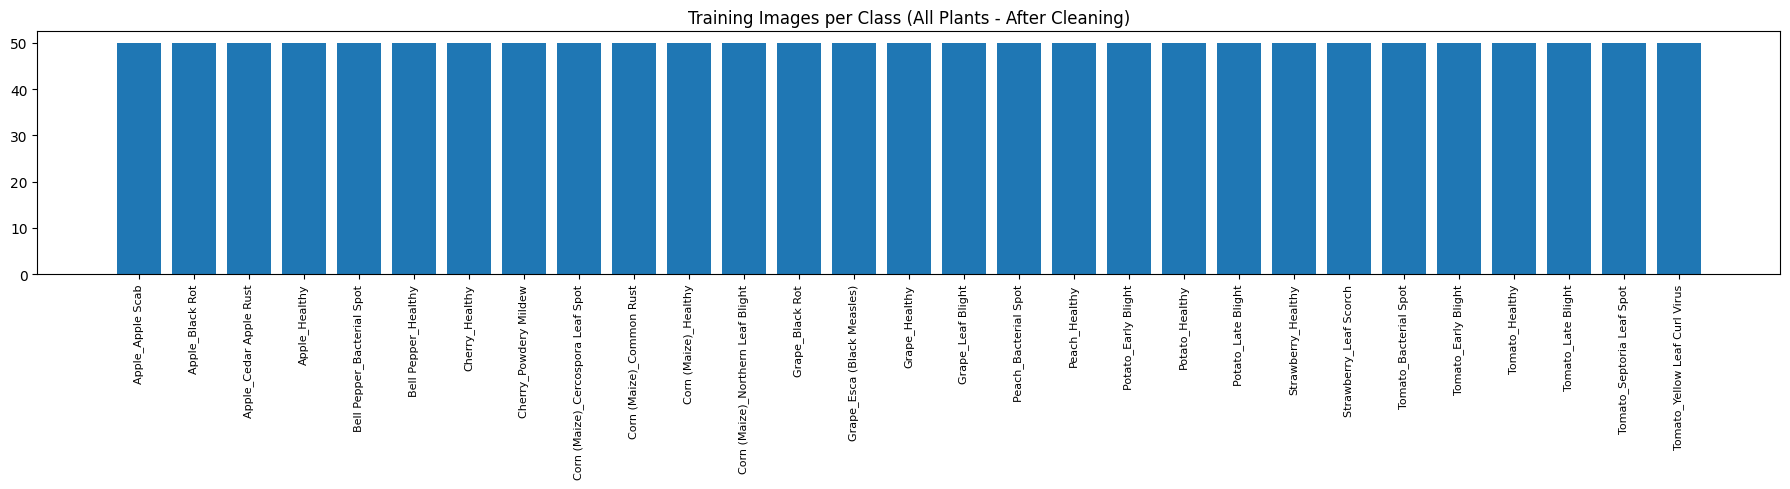

In [ ]:
plt.figure(figsize=(18, 5))
counts = np.bincount(y_train, minlength=len(class_names))
plt.bar(class_names, counts)
plt.xticks(rotation=90, fontsize=8)
plt.title("Training Images per Class (All Plants - After Cleaning)")
plt.tight_layout()
plt.show()

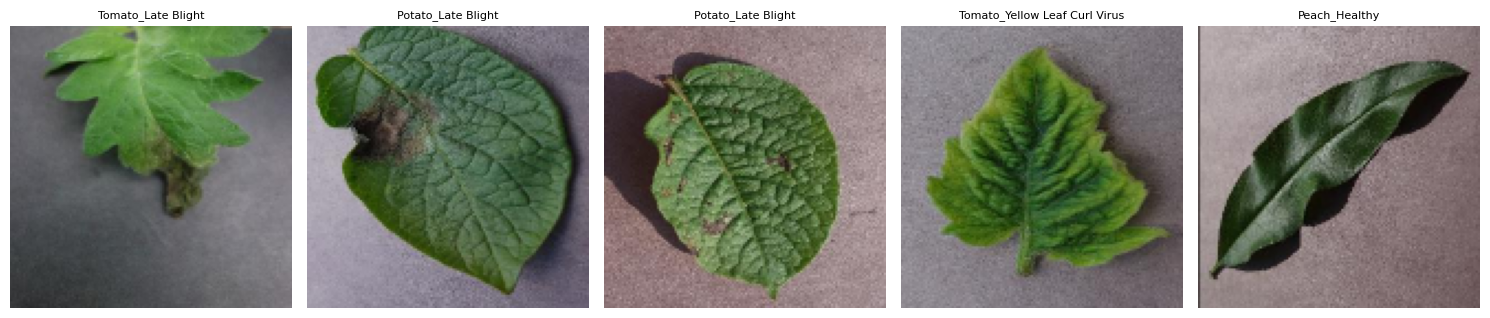

In [ ]:
plt.figure(figsize=(15, 3.5))
indices = np.random.choice(len(X_train), 5, replace=False)

for i, idx in enumerate(indices):
    plt.subplot(1, 5, i + 1)
    img_show = X_train[idx].astype("uint8") if X_train[idx].max() > 1 else X_train[idx]
    plt.imshow(img_show)
    plt.title(class_names[y_train[idx]], fontsize=8)
    plt.axis("off")

plt.tight_layout()
plt.show()